In [7]:
# Names

# Amanda Le (al58528)
# Hannah Fan (hlf583)
# Rianna Skaria (rrs3385)
# Prithikaa Sadagopan (ps35493)

# Predicting Sleep Debt Severity from Evening Technology Habits

## Introduction

Sleep debt occurs when an individual does not obtain sufficient
sleep relative to their sleep needs. Understanding the relationship
between evening technology habits and sleep debt may help identify
patterns associated with insufficient sleep.

In this project, we investigate whether sleep debt severity can
be predicted using demographic characteristics, evening phone
habits, and other lifestyle variables.

## Dataset

Our dataset contains 8,500 observations and 17 features describing
individuals' lifestyle habits, technology use, and sleep-related
measurements.

link: https://www.kaggle.com/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits

In [4]:
# standard headers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# load data set
sleep = pd.read_csv('bedtime_screentime_sleep_debt.csv')
print(sleep.shape)
display(sleep.head())

(8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [10]:
# check data types and non-null counts
sleep.info()

# count missing values in each column
missingCount = sleep.isna().sum()
print(missingCount)

# print the total number of missing values
print("Total missing values:", sleep.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   str    
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   str    
 3   occupation_type           8500 non-null   str    
 4   chronotype                8500 non-null   str    
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   str    
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_sleep_pct      

### Data Exploration and Analysis

In [11]:
# check for duplicate rows and duplicate user IDs
print("Duplicate rows:", sleep.duplicated().sum())
print("Unique user IDs:", sleep["user_id"].nunique())

# examine the target distribution
display(sleep["sleep_debt_category"].value_counts())
display(sleep["sleep_debt_category"].value_counts(normalize=True))

Duplicate rows: 0
Unique user IDs: 8500


sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

sleep_debt_category
Moderate Debt        0.524941
Mild Deficit         0.235765
Optimal Recovery     0.163176
Severe Sleep Debt    0.076118
Name: proportion, dtype: float64

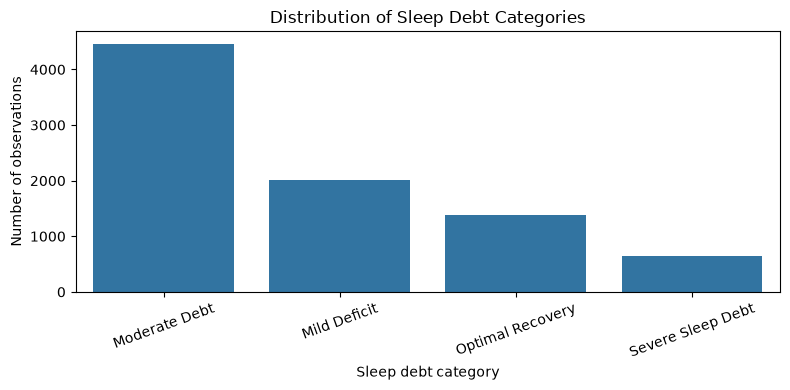

In [12]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=sleep,
    x="sleep_debt_category",
    order=sleep["sleep_debt_category"].value_counts().index
)
plt.title("Distribution of Sleep Debt Categories")
plt.xlabel("Sleep debt category")
plt.ylabel("Number of observations")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# The target distribution is imbalanced as shown in the chart. Moderate Sleep Debt represents about 52.5% of observations, while Severe Sleep Debt represents only 7.6%. This imbalance will be considered when evaluating our classification models.

In [28]:
# compare numeric variables across sleep-debt categories
numeric_to_compare = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "morning_alarm_snoozes",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "next_day_fatigue_score"
]

display(
    sleep.groupby("sleep_debt_category")[numeric_to_compare]
    .agg(["mean", "median"])
    .round(2)
)

age        bedtime_phone_minutes         \
                      mean median                  mean median   
sleep_debt_category                                              
Mild Deficit         34.37   32.0                 45.45   43.0   
Moderate Debt        34.38   32.0                 64.12   60.0   
Optimal Recovery     34.70   32.0                 33.51   30.0   
Severe Sleep Debt    33.45   30.0                123.60  125.0   

                    screen_brightness_pct        caffeine_post_5pm_mg         \
                                     mean median                 mean median   
sleep_debt_category                                                            
Mild Deficit                        55.37   56.0                33.03    0.0   
Moderate Debt                       54.52   55.0                31.56    0.0   
Optimal Recovery                    54.24   55.0                30.24    0.0   
Severe Sleep Debt                   60.80   60.0                51.66   25.0   

                    physical_activity_min         ... sleep_latency_min  \
                                     mean median  ...              mean   
sleep_debt_category                               ...                     
Mild Deficit                        35.27   35.0  ...             34.69   
Moderate Debt                       35.97   36.0  ...             42.37   
Optimal Recovery                    36.11   35.0  ...             28.92   
Severe Sleep Debt                   34.30   32.0  ...             72.70   

                           total_sleep_hours        deep_sleep_pct         \
                    median              mean median           mean median   
sleep_debt_category                                                         
Mild Deficit          33.4              7.23   7.21          22.09   22.3   
Moderate Debt         40.7              5.55   5.66          21.75   21.8   
Optimal Recovery      28.0              8.35   8.23          22.37   22.4   
Severe Sleep Debt     72.9              3.76   3.59          19.18   19.2   

                    rem_sleep_pct        next_day_fatigue_score         
                             mean median                   mean median  
sleep_debt_category                                                     
Mild Deficit                19.16   19.2                   1.83    1.4  
Moderate Debt               19.15   19.2                   4.68    4.6  
Optimal Recovery            19.19   19.2                   1.08    1.0  
Severe Sleep Debt           18.48   18.4                   9.58    9.9  

[4 rows x 22 columns]

In [ ]:
# Severe Sleep Debt showed the highest in bedtime phone usage, sleep latency, caffeine intake, alarm snoozes, and next-day fatigue, along with the lowest total sleep duration. Optimal Recovery showed the opposite patterns for most of these variables. Age was relatively consistent across categories, suggesting it may be less useful for distinguishing sleep-debt severity.

Numerical Feature Distributions:

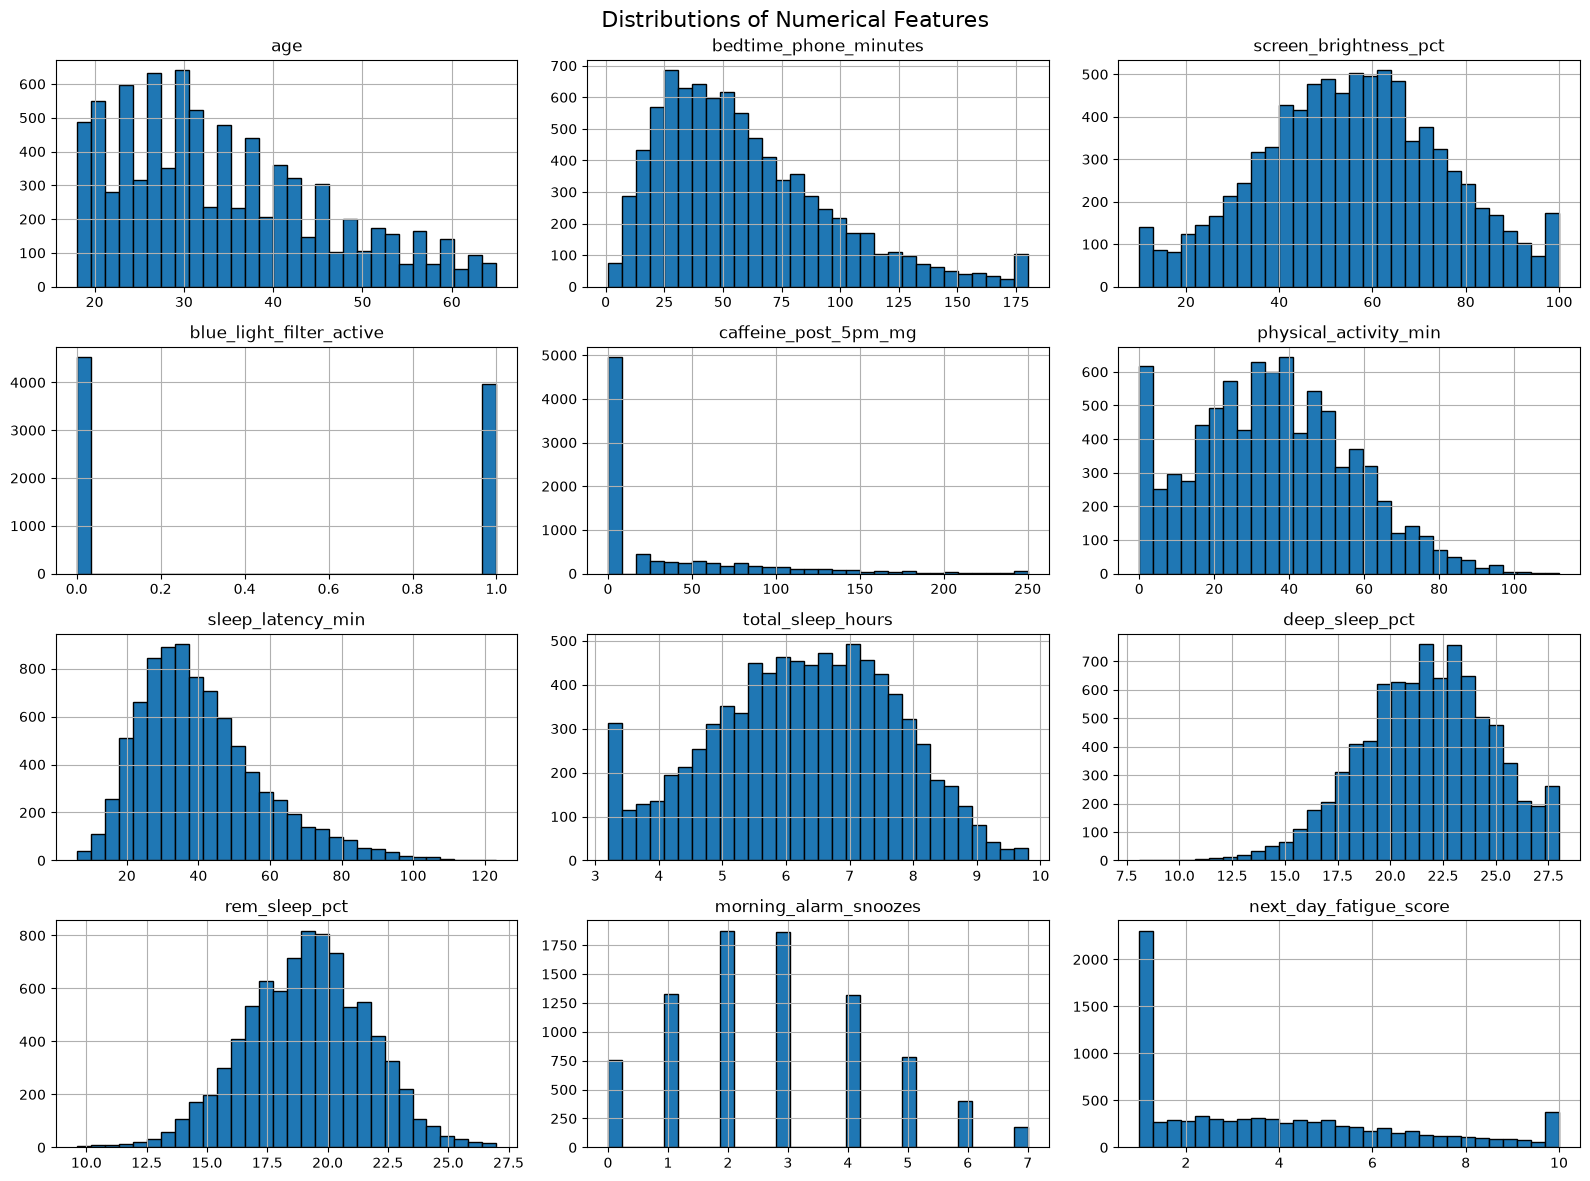

In [24]:
numeric_features = [
    col for col in sleep.select_dtypes(include=np.number).columns
    if col != "user_id"
]

# plot distributions
sleep[numeric_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [25]:
# summary statistics and skewness
distribution_summary = sleep[numeric_features].agg(
    ["mean", "median", "std", "min", "max"]
).T

distribution_summary["skewness"] = sleep[numeric_features].skew()

display(distribution_summary.round(2))

,mean,median,std,min,max,skewness
age,34.36,32.00,11.58,18.0,65.0,0.68
bedtime_phone_minutes,59.25,51.00,36.93,1.0,180.0,1.03
screen_brightness_pct,55.15,55.00,19.85,10.0,100.0,-0.01
blue_light_filter_active,0.47,0.00,0.50,0.0,1.0,0.13
caffeine_post_5pm_mg,33.22,0.00,51.94,0.0,250.0,1.78
physical_activity_min,35.70,35.00,20.82,0.0,112.0,0.26
sleep_latency_min,40.67,37.60,17.44,6.0,123.3,0.97
total_sleep_hours,6.27,6.33,1.45,3.2,9.8,-0.16
deep_sleep_pct,21.74,21.90,3.07,8.1,28.0,-0.26
rem_sleep_pct,19.11,19.10,2.55,9.6,27.0,-0.11


In [27]:
# Numerical Feature Distribution Analysis

# The numerical feature distributions revealed several differences in the characteristics of our dataset. Age, bedtime phone usage, evening caffeine consumption, sleep latency, and next-day fatigue were right-skewed, indicating that most observations were concentrated toward lower values. Evening caffeine consumption showed the strongest skewness (1.78), with a median of 0 mg compared to a mean of 33.22 mg.

# Screen brightness, total sleep hours, and REM sleep percentage were approximately normally distributed. Deep sleep percentage showed a slight left skew, while physical activity was relatively symmetric. Blue-light filter usage was binary, and morning alarm snoozes followed a discrete distribution.

# These suggest that certain features may benefit from transformations or binning. Additionally, the differences in numerical scales make standardization important for algorithms that uses distance (K-Means, KNN). The right-skewed features will also be investigated further during anomaly detection.

Exploring relationships between features:

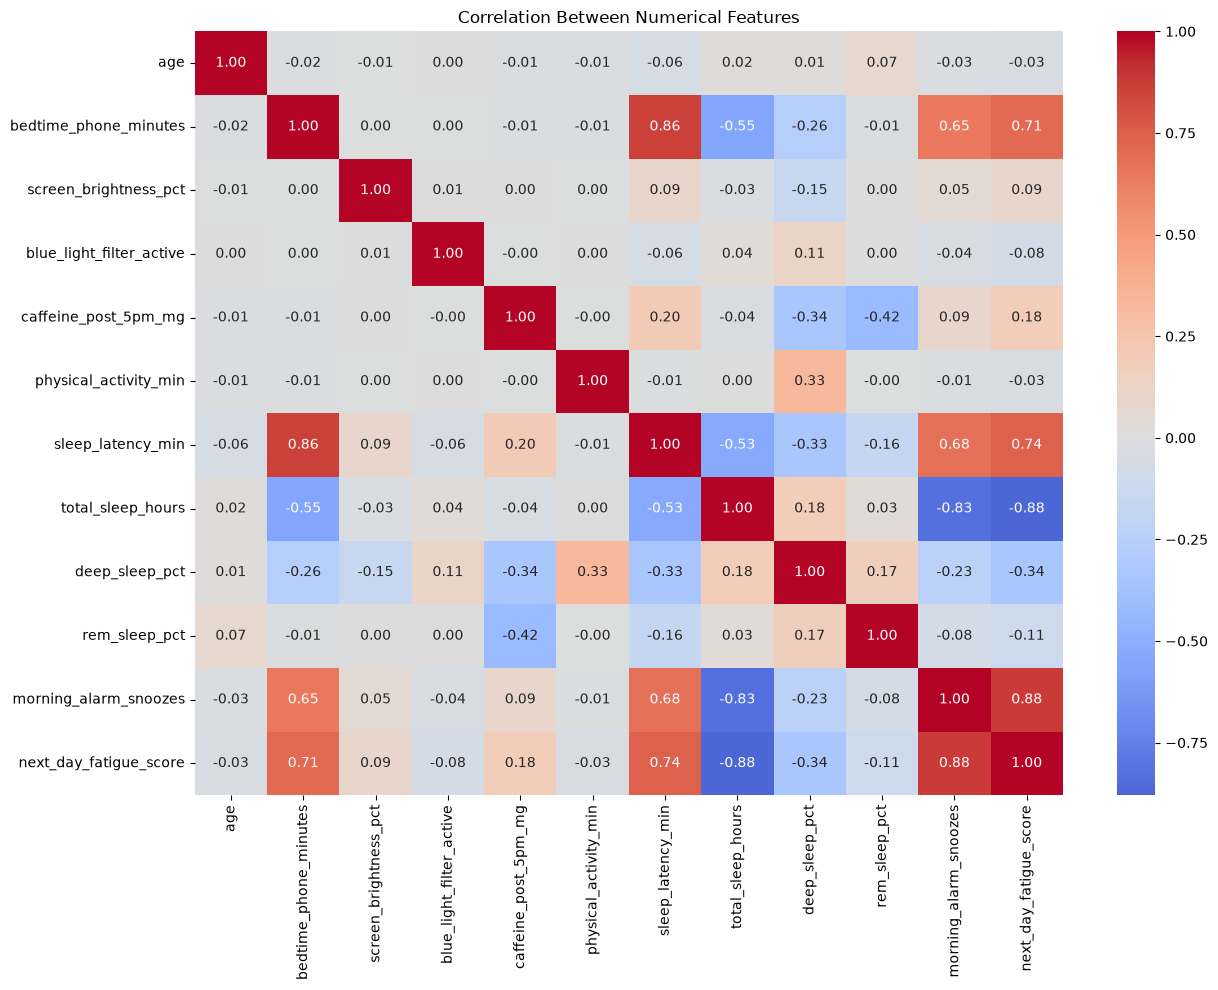

In [29]:
# calculate correlations between numerical features
correlation = sleep[numeric_features].corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
# The correlation analysis shows a strong positive relationship between bedtime phone usage and sleep latency (0.86), suggesting that people with more bedtime phone usage tend to take longer to fall asleep.
# Total sleep hours had a strong negative relationship with next-day fatigue (-0.88). 
# Evening caffeine had only a weak positive correlation with sleep latency (0.20). 
# These relationships suggest that certain lifestyle and features may provide useful information for understanding sleep patterns.

In [30]:
# compare chronotype with sleep debt category
chronotype_comparison = pd.crosstab(
    sleep["chronotype"],
    sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(chronotype_comparison.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
chronotype,,,,
Intermediate,32.04,50.13,11.98,5.85
Morning Lark,30.67,24.39,42.36,2.59
Night Owl,3.95,81.02,0.20,14.83


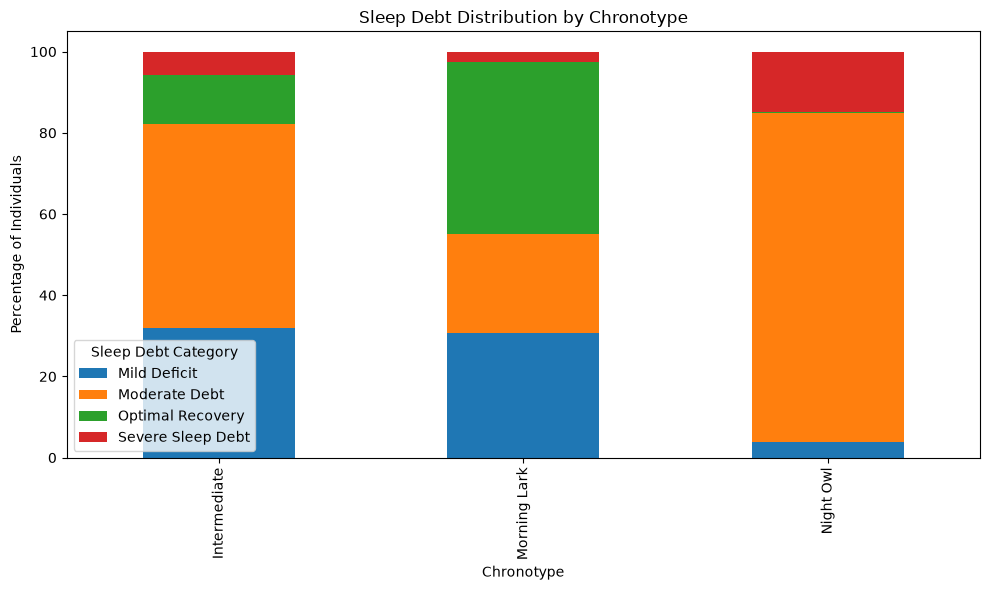

In [31]:
chronotype_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sleep Debt Distribution by Chronotype")
plt.xlabel("Chronotype")
plt.ylabel("Percentage of Individuals")
plt.legend(title="Sleep Debt Category")
plt.tight_layout()
plt.show()

In [33]:
# compare occupation with sleep debt category
occupation_comparison = pd.crosstab(
    sleep["occupation_type"],
    sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(occupation_comparison.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
occupation_type,,,,
Corporate 9-to-5,25.44,49.44,18.68,6.45
Freelance / Creative,25.97,50.94,16.20,6.88
Healthcare / Shift Worker,8.73,71.41,1.60,18.25
Remote Tech,24.88,50.93,18.44,5.74
Student,26.39,49.14,18.50,5.98


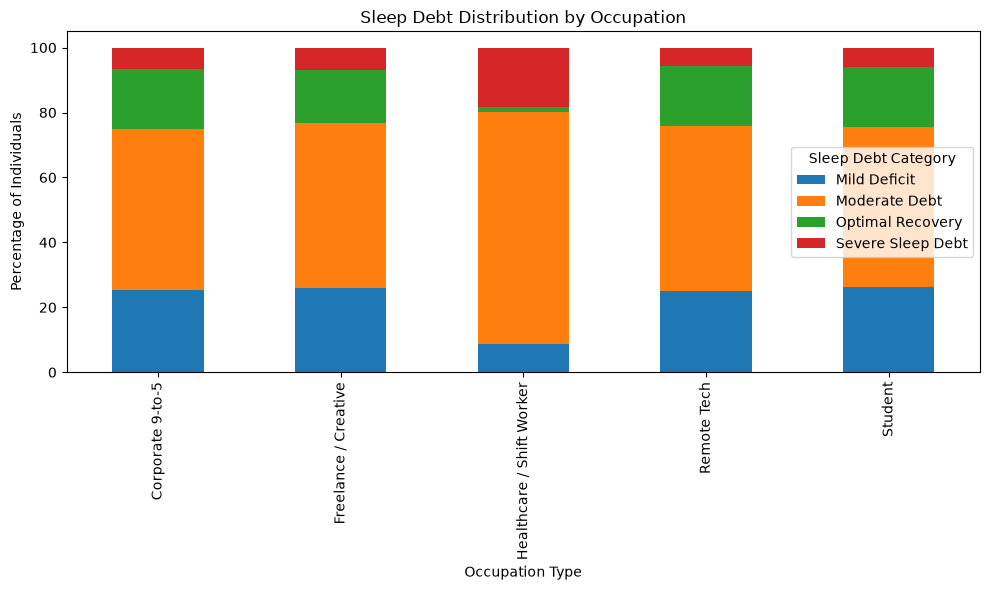

In [34]:
occupation_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sleep Debt Distribution by Occupation")
plt.xlabel("Occupation Type")
plt.ylabel("Percentage of Individuals")
plt.legend(title="Sleep Debt Category")
plt.tight_layout()
plt.show()

In [35]:
# compare bedtime app with sleep debt category
bedtime_app_comparison = pd.crosstab(
    sleep["primary_bedtime_app"],
    sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(bedtime_app_comparison.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
primary_bedtime_app,,,,
Instagram / Reddit,23.50,53.19,15.64,7.67
Messaging / Chat,24.44,51.59,17.36,6.61
News / Reading,26.34,53.52,16.11,4.03
Streaming (Netflix/Hulu),23.98,52.81,17.60,5.61
TikTok / Reels,22.16,51.91,15.10,10.83
YouTube,23.76,52.44,17.01,6.79


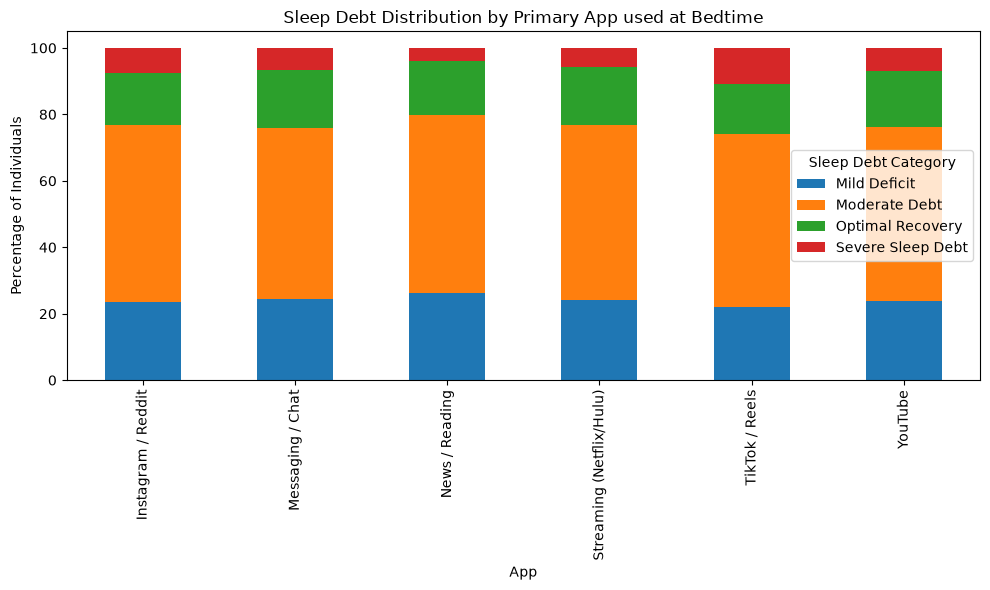

In [36]:
bedtime_app_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sleep Debt Distribution by Primary App used at Bedtime")
plt.xlabel("App")
plt.ylabel("Percentage of Individuals")
plt.legend(title="Sleep Debt Category")
plt.tight_layout()
plt.show()

In [ ]:
# Chronotype showed notable differences across sleep-debt categories. Morning Larks had the highest proportion of Optimal Recovery (42.36%), while Night Owls were heavily concentrated in Moderate Debt (81.02%) and had the highest proportion of Severe Sleep Debt (14.83%).

# Occupation type also showed differences, especially for Healthcare / Shift Workers, who had the highest Severe Sleep Debt percentage (18.25%).

# Primary bedtime app showed smaller differences. TikTok / Reels usage had the highest Severe Sleep Debt percentage (10.83%).

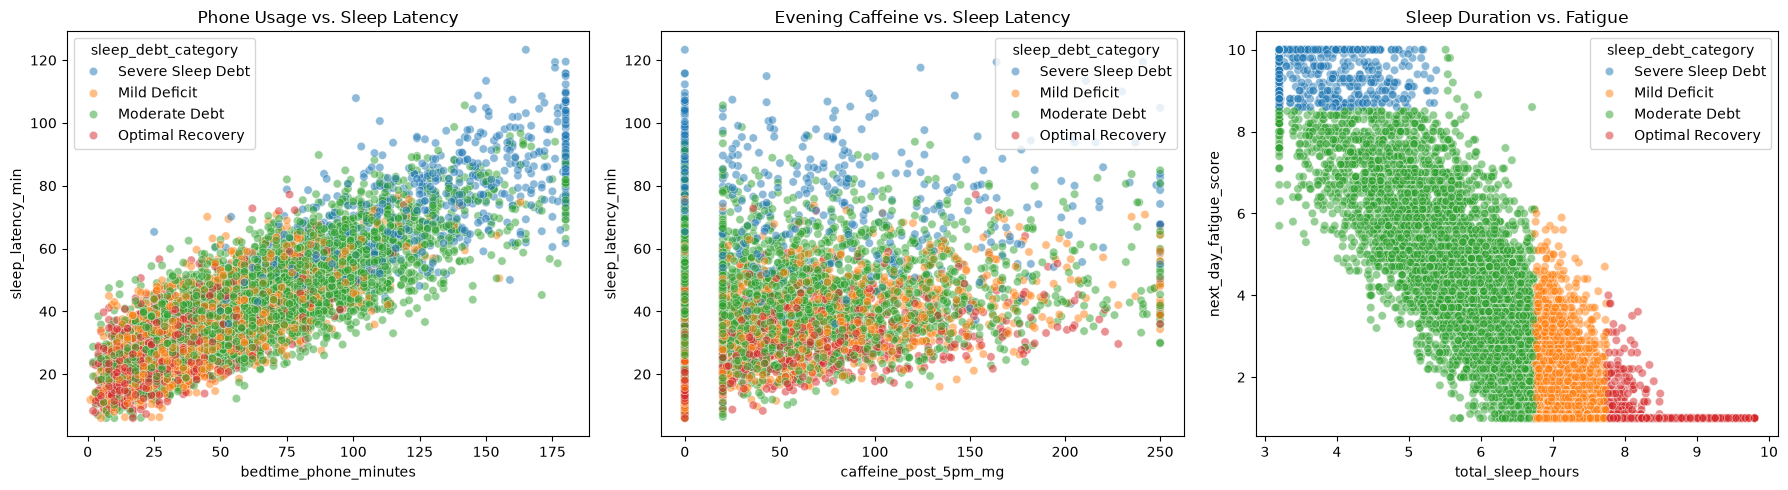

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=sleep,
    x="bedtime_phone_minutes",
    y="sleep_latency_min",
    hue="sleep_debt_category",
    alpha=0.5,
    ax=axes[0]
)

sns.scatterplot(
    data=sleep,
    x="caffeine_post_5pm_mg",
    y="sleep_latency_min",
    hue="sleep_debt_category",
    alpha=0.5,
    ax=axes[1]
)

sns.scatterplot(
    data=sleep,
    x="total_sleep_hours",
    y="next_day_fatigue_score",
    hue="sleep_debt_category",
    alpha=0.5,
    ax=axes[2]
)

axes[0].set_title("Phone Usage vs. Sleep Latency")
axes[1].set_title("Evening Caffeine vs. Sleep Latency")
axes[2].set_title("Sleep Duration vs. Fatigue")

plt.tight_layout()
plt.show()

K-Means clustering

In [40]:
# K-means calculates distances between observations, so we must standardize and one hot encode our data first
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# select lifestyle and technology features
# exclude sleep related measures that could make clusters reflect exisiting outcomes rather than the habits we are exploring
cluster_features = [
    "age",
    "gender",
    "occupation_type",
    "chronotype",
    "bedtime_phone_minutes",
    "primary_bedtime_app",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min"
]

# separate numerical and categorical features
numeric_features_cluster = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min"
]

categorical_features_cluster = [
    "gender",
    "occupation_type",
    "chronotype",
    "primary_bedtime_app"
]

# standardize numerical features and encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_cluster),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_cluster)
    ]
)

# transform the dataset
X_cluster = preprocessor.fit_transform(sleep[cluster_features])

print("Original feature shape:", sleep[cluster_features].shape)
print("Transformed feature shape:", X_cluster.shape)


Original feature shape: (8500, 10)
Transformed feature shape: (8500, 23)


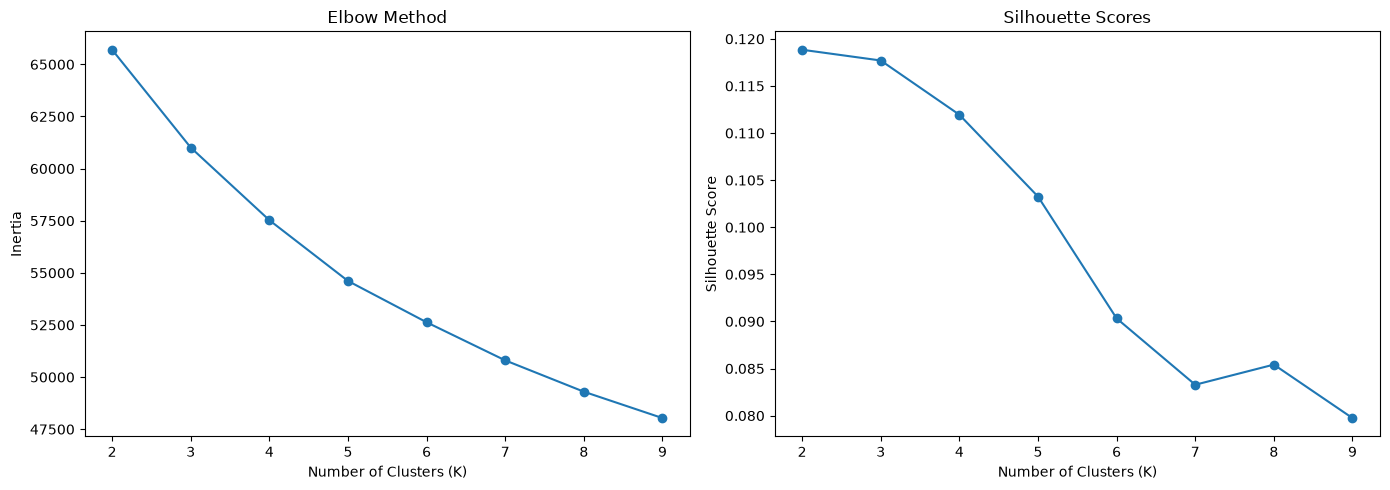

In [43]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# test different numbers of clusters
k_values = range(2, 10)

inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(
            X_cluster,
            cluster_labels,
            sample_size=2000,
            random_state=42
        )
    )

# plot the results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [ ]:
# K = 2 has the highest silhouette score (0.118) and K = 3 is very similar with 0.1177
# We will fit at K = 3 despite K = 2 having a higher score since 3 clusters may provide more useful detail when profiling different lifestyle groups 

In [ ]:
# fit K-Means using 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

clustered_sleep = sleep.copy()

# add cluster assignments
clustered_sleep["cluster"] = cluster_labels

# examine the number of observations in each cluster
print(clustered_sleep["cluster"].value_counts().sort_index())

cluster
0    3802
1    3401
2    1297
Name: count, dtype: int64


In [45]:
# compare average numerical features across clusters
cluster_summary = clustered_sleep.groupby("cluster")[
    numeric_features_cluster
].mean()

display(cluster_summary.round(2))

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
cluster,,,,,,
0,34.38,60.02,54.83,0.00,14.45,35.62
1,34.52,59.25,55.38,1.00,15.06,35.82
2,33.87,57.00,55.51,0.44,135.90,35.63


In [46]:
# examine chronotype distribution within each cluster
display(
    pd.crosstab(
        clustered_sleep["cluster"],
        clustered_sleep["chronotype"],
        normalize="index"
    ).round(3) * 100
)

# examine occupation distribution within each cluster
display(
    pd.crosstab(
        clustered_sleep["cluster"],
        clustered_sleep["occupation_type"],
        normalize="index"
    ).round(3) * 100
)

chronotype,Intermediate,Morning Lark,Night Owl
cluster,,,
0,46.4,25.2,28.3
1,45.2,25.4,29.4
2,44.5,26.2,29.3


occupation_type,Corporate 9-to-5,Freelance / Creative,Healthcare / Shift Worker,Remote Tech,Student
cluster,,,,,
0,38.6,12.6,14.0,19.3,15.5
1,27.6,8.0,9.0,31.6,23.8
2,33.5,11.4,12.0,25.9,17.1


In [ ]:
# compare clusters against sleep-debt severity
cluster_sleep_debt = pd.crosstab(
    clustered_sleep["cluster"],
    clustered_sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(cluster_sleep_debt.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
cluster,,,,
0,22.09,53.05,16.28,8.57
1,24.90,52.98,17.11,5.00
2,24.44,49.58,14.34,11.64


In [ ]:
# The K-Means results identified three groups with relatively balanced cluster sizes. 

# The numerical and categorical summaries showed some differences in lifestyle characteristics across clusters, although age and bedtime phone usage were relatively similar.

# The distribution of sleep-debt categories also differed across clusters. Cluster 2 had the highest proportion of Severe Sleep Debt (11.64%), while Cluster 1 had the lowest (5.00%).

# However, the low silhouette scores suggest that the clusters are not strongly separated. These results indicate that lifestyle characteristics may capture some differences in sleep-debt patterns, but the discovered groups are not clearly distinct.

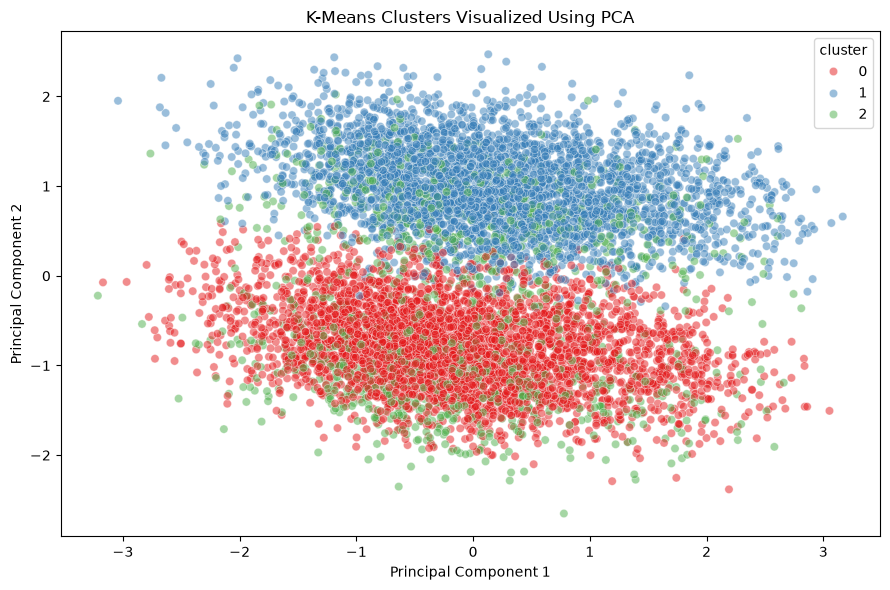

Explained variance: [0.1172266  0.11656228]
Total variance explained: 0.23378887871451615


In [ ]:
from sklearn.decomposition import PCA

# reduce the transformed features to two dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

# create a dataframe for visualization
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": cluster_labels
})

# plot the clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set1",
    alpha=0.5
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

# examine how much variance the two components explain
print("Explained variance:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

In [ ]:
# PCA reduced the 23 transformed features to two principal components for visualization. The first component explained 11.72% of the variance, and the second explained 11.66%, for a combined explained variance of 23.38%.

# The PCA visualization shows considerable overlap between the red and blue clusters, while the green cluster appears more spread out.

# There is no clear separation between all three groups in the two-dimensional projection. However, the first two principal components explain only 23.38% of the total variance, so the visualization may not capture all of the separation present in the original feature space.

Isolation Forest: detecting anonmolies

In [49]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    contamination=0.05,
    random_state=42
)

# identify anomalies
anomaly_predictions = isolation_forest.fit_predict(X_cluster)


sleep_with_anomalies = sleep.copy()

# add anomaly labels
sleep_with_anomalies["anomaly"] = anomaly_predictions

# count normal observations and anomalies
print(sleep_with_anomalies["anomaly"].value_counts())

anomaly
 1    8075
-1     425
Name: count, dtype: int64


In [50]:
contamination_values = [0.01, 0.05, 0.10]

anomaly_results = []

for contamination in contamination_values:
    model = IsolationForest(
        contamination=contamination,
        random_state=42
    )

    predictions = model.fit_predict(X_cluster)

    anomaly_count = (predictions == -1).sum()

    anomaly_results.append({
        "Contamination": contamination,
        "Anomaly Count": anomaly_count,
        "Anomaly Percentage": (anomaly_count / len(sleep)) * 100
    })

anomaly_summary = pd.DataFrame(anomaly_results)

display(anomaly_summary.round(2))

,Contamination,Anomaly Count,Anomaly Percentage
0,0.01,85,1.0
1,0.05,425,5.0
2,0.10,850,10.0


In [ ]:
# This shows that the contamination parameter controls how many observations the model flags. We will use 5% as a reasonable point for exploration, but it isn't evidence that 5% of the population is truly anomalous

In [51]:
# separate normal observations and anomalies
anomalies = sleep_with_anomalies[
    sleep_with_anomalies["anomaly"] == -1
]

normal_observations = sleep_with_anomalies[
    sleep_with_anomalies["anomaly"] == 1
]

print("Number of anomalies:", len(anomalies))
print("Number of normal observations:", len(normal_observations))

# examine some detected anomalies
display(anomalies[cluster_features].head(10))

Number of anomalies: 425
Number of normal observations: 8075


,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
3,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49
69,63,Female,Healthcare / Shift Worker,Night Owl,165,YouTube,45,1,0,26
112,55,Non-Binary,Remote Tech,Intermediate,40,Streaming (Netflix/Hulu),67,0,0,69
120,45,Non-Binary,Corporate 9-to-5,Night Owl,54,YouTube,16,1,0,27
140,59,Male,Student,Morning Lark,29,Instagram / Reddit,55,0,221,48
156,39,Male,Healthcare / Shift Worker,Night Owl,25,News / Reading,58,0,203,27
168,19,Female,Healthcare / Shift Worker,Intermediate,42,Instagram / Reddit,98,0,196,42
235,41,Non-Binary,Student,Intermediate,130,YouTube,100,1,0,64
247,60,Female,Healthcare / Shift Worker,Night Owl,75,Streaming (Netflix/Hulu),68,1,51,46
248,59,Female,Healthcare / Shift Worker,Night Owl,67,Messaging / Chat,59,1,0,17


In [52]:
anomaly_comparison = sleep_with_anomalies.groupby("anomaly")[
    numeric_features_cluster
].mean()

anomaly_comparison.index = anomaly_comparison.index.map({
    1: "Normal",
    -1: "Anomaly"
})

display(anomaly_comparison.round(2))

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
anomaly,,,,,,
Anomaly,40.30,69.20,56.21,0.50,72.44,37.63
Normal,34.04,58.73,55.10,0.47,31.16,35.60


In [54]:
anomaly_sleep_debt = pd.crosstab(
    sleep_with_anomalies["anomaly"],
    sleep_with_anomalies["sleep_debt_category"],
    normalize="index"
) * 100

anomaly_sleep_debt.index = anomaly_sleep_debt.index.map({
    1: "Normal",
    -1: "Anomaly"
})

display(anomaly_sleep_debt.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
anomaly,,,,
Anomaly,20.24,47.53,15.29,16.94
Normal,23.75,52.76,16.37,7.12


In [ ]:
# Isolation Forest identified 425 anomalies (5% of the dataset) using a contamination setting of 0.05.

# Compared with normal observations, anomalies had higher average bedtime phone usage (69.20 vs. 58.73 minutes), evening caffeine consumption (72.44 vs. 31.16 mg), and age (40.30 vs. 34.04).

# The most noticable difference appeared in sleep-debt severity. Severe Sleep Debt represented 16.94% of anomalies, compared with 7.12% of normal observations.

# This suggests that unusual combinations of lifestyle and technology habits may be associated with greater sleep-debt severity. However, anomalies are not necessarily incorrect observations, so we will retain them rather than automatically removing them from the dataset.